# ❤️ Machine Learning-Based Heart Disease Prediction System

**Project:** Internship Cardiovascular Disease Prediction  
**Dataset:** Cardiovascular Disease Dataset (`cardio_train.csv`)  
**Author:** [Your Name]  
**Date:** October 2026

---

> **⚠️ Disclaimer:** All predictions generated by the model in this notebook are based on  
> statistical patterns in a population-level dataset. They are **NOT** a clinical diagnosis  
> and should **NOT** replace professional medical advice.

---

## Table of Contents
1. [Environment Setup](#setup)
2. [Data Loading & Inspection](#loading)
3. [Data Cleaning & Preprocessing](#cleaning)
4. [Exploratory Data Analysis (EDA)](#eda)
5. [Correlation Analysis](#correlation)
6. [Train/Test Split & Pipelines](#split)
7. [Baseline Cross-Validation](#cv)
8. [Hyperparameter Tuning](#tuning)
9. [Test-Set Evaluation & Comparison](#evaluation)
10. [Final Model Selection & Saving](#final)
11. [Prediction Function Demo](#prediction)


## 1. Environment Setup <a id='setup'></a>

In [1]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_validate, StratifiedShuffleSplit,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve,
    ConfusionMatrixDisplay, classification_report,
)

warnings.filterwarnings("ignore")

# ── Reproducibility ──────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ── Plotting style ───────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13})

# ── Paths ────────────────────────────────────────────────────
BASE_DIR   = os.path.abspath(os.path.join(os.getcwd(), ".."))
DATA_PATH  = os.path.join(BASE_DIR, "data",    "cardio_train.csv")
FIGS_DIR   = os.path.join(BASE_DIR, "outputs", "figures")
MODELS_DIR = os.path.join(BASE_DIR, "models")
os.makedirs(FIGS_DIR,   exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Allow importing src modules
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Numpy :", np.__version__)
print("Data path exists:", os.path.exists(DATA_PATH))
print("Base dir:", BASE_DIR)


Python: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.0.0
Numpy : 2.4.1
Data path exists: True
Base dir: D:\Project\heart-disease-prediction


## 2. Data Loading & Inspection <a id='loading'></a>

We first confirm the file separator, then inspect every column for data type,
missing values, duplicates, and basic statistics before touching anything.


In [2]:
# ── Load (semicolon-separated) ────────────────────────────────
df_raw = pd.read_csv(DATA_PATH, sep=";")

print(f"Raw shape : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Columns   : {df_raw.columns.tolist()}")
df_raw.head()


Raw shape : 70,000 rows × 13 columns
Columns   : ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
# ── Data types & missing values ───────────────────────────────
info = pd.DataFrame({
    "dtype":   df_raw.dtypes,
    "missing": df_raw.isnull().sum(),
    "pct_missing": (df_raw.isnull().sum() / len(df_raw) * 100).round(2),
    "nunique": df_raw.nunique(),
})
print(info.to_string())


               dtype  missing  pct_missing  nunique
id             int64        0          0.0    70000
age            int64        0          0.0     8076
gender         int64        0          0.0        2
height         int64        0          0.0      109
weight       float64        0          0.0      287
ap_hi          int64        0          0.0      153
ap_lo          int64        0          0.0      157
cholesterol    int64        0          0.0        3
gluc           int64        0          0.0        3
smoke          int64        0          0.0        2
alco           int64        0          0.0        2
active         int64        0          0.0        2
cardio         int64        0          0.0        2


In [4]:
# ── Descriptive statistics ────────────────────────────────────
df_raw.describe().round(2)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.00,70000.0,70000.0
mean,49972.42,19468.87,1.35,164.36,74.21,128.82,96.63,1.37,1.23,0.09,0.05,0.8,0.5
std,28851.30,2467.25,0.48,8.21,14.40,154.01,188.47,0.68,0.57,0.28,0.23,0.4,0.5
min,0.00,10798.00,1.00,55.00,10.00,-150.00,-70.00,1.00,1.00,0.00,0.00,0.0,0.0
25%,25006.75,17664.00,1.00,159.00,65.00,120.00,80.00,1.00,1.00,0.00,0.00,1.0,0.0
50%,50001.50,19703.00,1.00,165.00,72.00,120.00,80.00,1.00,1.00,0.00,0.00,1.0,0.0
75%,74889.25,21327.00,2.00,170.00,82.00,140.00,90.00,2.00,1.00,0.00,0.00,1.0,1.0
max,99999.00,23713.00,2.00,250.00,200.00,16020.00,11000.00,3.00,3.00,1.00,1.00,1.0,1.0


In [5]:
# ── Target distribution ───────────────────────────────────────
print("Target (cardio) distribution:")
print(df_raw["cardio"].value_counts())
print(f"Class balance: {df_raw['cardio'].mean()*100:.1f}% positive")

print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")
print(f"Age range: {df_raw['age'].min()} – {df_raw['age'].max()} days "
      f"({df_raw['age'].min()/365.25:.1f} – {df_raw['age'].max()/365.25:.1f} years)")


Target (cardio) distribution:
cardio
0    35021
1    34979
Name: count, dtype: int64
Class balance: 50.0% positive

Duplicate rows: 0
Age range: 10798 – 23713 days (29.6 – 64.9 years)


## 3. Data Cleaning & Preprocessing <a id='cleaning'></a>

Cleaning is performed on a **working copy** – the raw DataFrame is never mutated.
Every removal/modification is documented with a row count.


In [6]:
from src.preprocessing import load_and_clean, get_feature_columns

df_clean, cleaning_log = load_and_clean(DATA_PATH)
print(f"\nCleaned dataset shape: {df_clean.shape}")
df_clean.describe().round(2)



=== Step 1: Loading dataset ===


  [CLEAN] Loaded raw dataset: 70,000 rows × 13 columns
  [CLEAN] Separator: semicolon (';')
  [CLEAN] Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

=== Step 2: Inspection ===
  [CLEAN] Data types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
  [CLEAN] Missing values per column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
  [CLEAN] Total missing cells: 0
  [CLEAN] Dropped column 'id' (surrogate key, not a feature).

=== Step 3: Duplicate removal ===


  [CLEAN] Duplicate rows removed: 24 (0.03%)

=== Step 4: Age conversion ===
  [CLEAN] Converted 'age' from days to years (div 365.25). Range now: 29.6 – 64.9 years.

=== Step 5: Blood pressure cleaning ===
  [CLEAN] Non-positive BP readings: 29
  [CLEAN] Implausible BP (systolic outside 60–250 mmHg or diastolic outside 40–180 mmHg): 1228
  [CLEAN] Inverted BP (diastolic >= systolic): 1236
  [CLEAN] Total rows removed for BP issues: 1329 (1.90%)

=== Step 6: Height and weight cleaning ===
  [CLEAN] Implausible height (outside 100–220 cm) or weight (outside 30–200 kg): 33
  [CLEAN] Total rows removed for height/weight issues: 33 (0.05%)

=== Step 7: BMI calculation ===
  [CLEAN] BMI computed: weight(kg) / height(m)². Range: 10.7 – 152.6

=== Step 8: BMI plausibility filter ===


  [CLEAN] Rows removed for implausible BMI (outside 10–70): 11
  [CLEAN] 
CLEANING SUMMARY: started with 70,000 rows, removed 1,397 rows total (2.00%), retained 68,603 rows.
  [CLEAN] Final cleaned dataset shape: (68603, 13)

Cleaned dataset shape: (68603, 13)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
count,68603.00,68603.00,68603.00,68603.00,68603.00,68603.00,68603.00,68603.00,68603.00,68603.00,68603.0,68603.00,68603.00
mean,53.29,1.35,164.40,74.11,126.67,81.31,1.36,1.23,0.09,0.05,0.8,0.49,27.46
std,6.76,0.48,7.95,14.28,16.69,9.45,0.68,0.57,0.28,0.22,0.4,0.50,5.26
min,29.60,1.00,100.00,30.00,60.00,40.00,1.00,1.00,0.00,0.00,0.0,0.00,10.73
25%,48.30,1.00,159.00,65.00,120.00,80.00,1.00,1.00,0.00,0.00,1.0,0.00,23.88
50%,53.90,1.00,165.00,72.00,120.00,80.00,1.00,1.00,0.00,0.00,1.0,0.00,26.35
75%,58.40,2.00,170.00,82.00,140.00,90.00,2.00,1.00,0.00,0.00,1.0,1.00,30.12
max,64.90,2.00,207.00,200.00,240.00,180.00,3.00,3.00,1.00,1.00,1.0,1.00,70.00


In [7]:
# ── Print full cleaning log ───────────────────────────────────
print("\n=== CLEANING LOG ===")
for entry in cleaning_log:
    print(entry)



=== CLEANING LOG ===
Loaded raw dataset: 70,000 rows × 13 columns
Separator: semicolon (';')
Columns: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
Data types:
id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
Missing values per column:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
Total missing cells: 0
Dropped column 'id' (surrogate key, not a feature).
Duplicate rows removed: 24 (0.03%)
Converted 'age' from days to years (div 365.25). Range now: 29.6 – 64.9 years.
Non-positive BP readings: 2

In [8]:
# ── Before/after row counts ───────────────────────────────────
n_raw     = df_raw.shape[0]
n_cleaned = df_clean.shape[0]
n_removed = n_raw - n_cleaned
print(f"Raw rows    : {n_raw:,}")
print(f"Cleaned rows: {n_cleaned:,}")
print(f"Removed     : {n_removed:,}  ({n_removed/n_raw*100:.2f}%)")


Raw rows    : 70,000
Cleaned rows: 68,603
Removed     : 1,397  (2.00%)


## 4. Exploratory Data Analysis (EDA) <a id='eda'></a>

All visualisations are produced from the **cleaned** dataset.
Short interpretations follow each plot.


### 4.1 Target Class Distribution

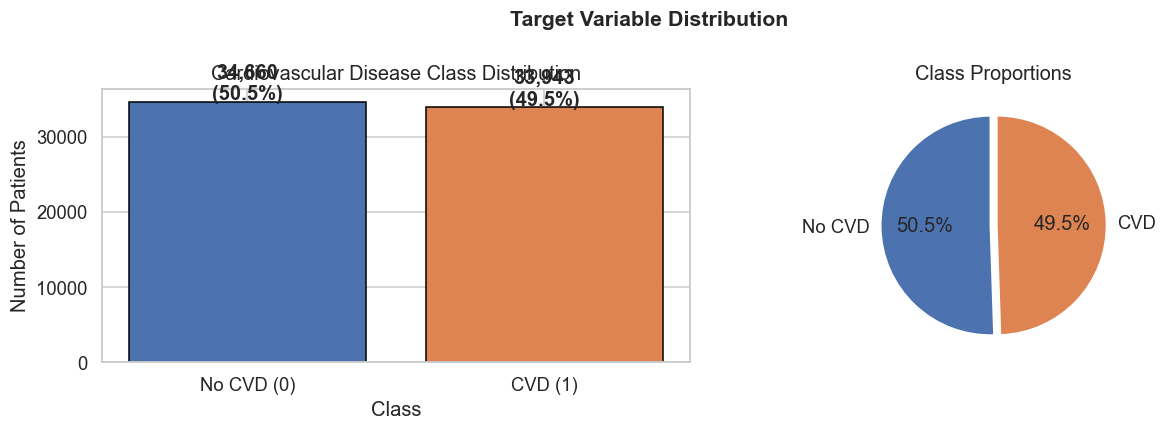


Interpretation: The dataset is nearly perfectly balanced (50/50),
which means accuracy is a fair baseline metric and no class-weight
adjustments are required.  However, for cardiovascular screening,
we still prioritise recall over raw accuracy.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
counts = df_clean["cardio"].value_counts().sort_index()
axes[0].bar(
    ["No CVD (0)", "CVD (1)"],
    counts.values,
    color=["#4C72B0", "#DD8452"],
    edgecolor="black",
)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 200, f"{v:,}\n({v/len(df_clean)*100:.1f}%)",
                 ha="center", fontweight="bold")
axes[0].set_title("Cardiovascular Disease Class Distribution")
axes[0].set_ylabel("Number of Patients")
axes[0].set_xlabel("Class")

# Pie chart
axes[1].pie(
    counts.values,
    labels=["No CVD", "CVD"],
    autopct="%1.1f%%",
    colors=["#4C72B0", "#DD8452"],
    startangle=90,
    explode=(0.03, 0.03),
)
axes[1].set_title("Class Proportions")

plt.suptitle("Target Variable Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "01_target_distribution.png"), dpi=150)
plt.show()
print("\nInterpretation: The dataset is nearly perfectly balanced (50/50),")
print("which means accuracy is a fair baseline metric and no class-weight")
print("adjustments are required.  However, for cardiovascular screening,")
print("we still prioritise recall over raw accuracy.")


### 4.2 Age Distribution & CVD Prevalence by Age

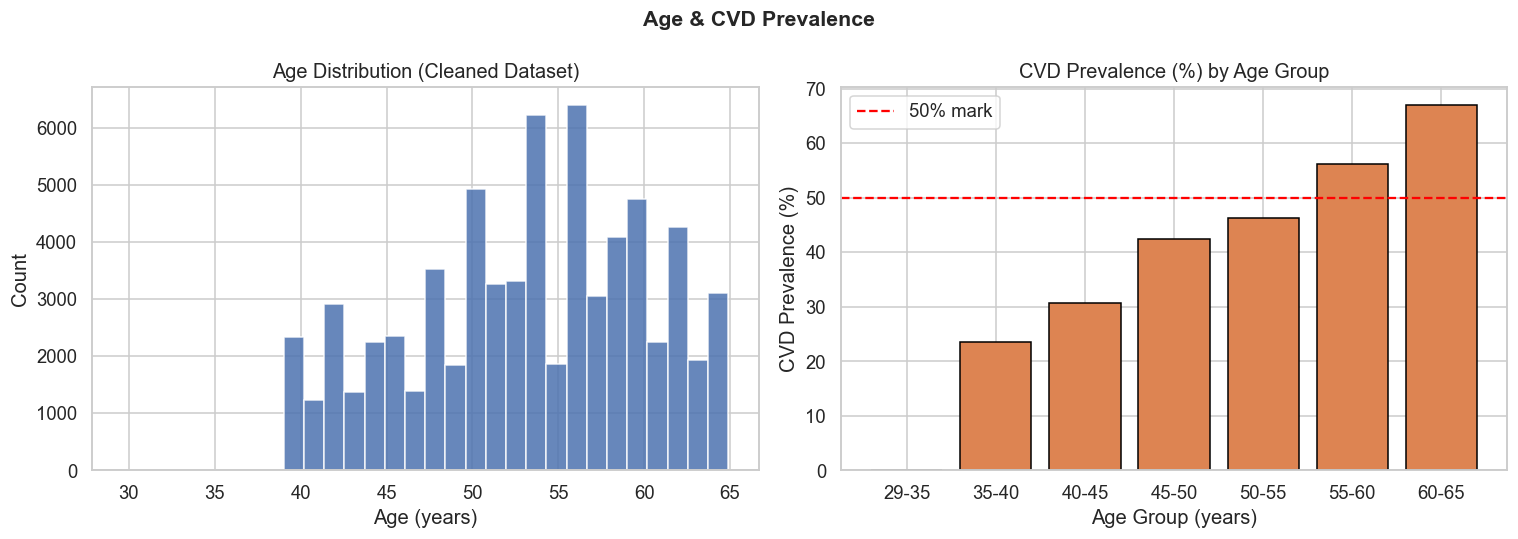

Interpretation: CVD prevalence increases steeply with age, rising
from ~25% in the 29-35 group to ~65% in the 60-65 group.
This is consistent with clinical literature. Age is likely to be
one of the most predictive features.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall age distribution
axes[0].hist(
    df_clean["age"], bins=30, color="#4C72B0", edgecolor="white",
    alpha=0.85,
)
axes[0].set_title("Age Distribution (Cleaned Dataset)")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Count")

# CVD prevalence by age bin
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[29, 35, 40, 45, 50, 55, 60, 66],
    labels=["29-35","35-40","40-45","45-50","50-55","55-60","60-65"],
)
prev = (
    df_clean.groupby("age_group", observed=True)["cardio"]
    .mean()
    .mul(100)
    .reset_index()
)
axes[1].bar(
    prev["age_group"].astype(str),
    prev["cardio"],
    color="#DD8452", edgecolor="black",
)
axes[1].axhline(50, color="red", linestyle="--", label="50% mark")
axes[1].set_title("CVD Prevalence (%) by Age Group")
axes[1].set_xlabel("Age Group (years)")
axes[1].set_ylabel("CVD Prevalence (%)")
axes[1].legend()

plt.suptitle("Age & CVD Prevalence", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "02_age_distribution.png"), dpi=150)
plt.show()
print("Interpretation: CVD prevalence increases steeply with age, rising")
print("from ~25% in the 29-35 group to ~65% in the 60-65 group.")
print("This is consistent with clinical literature. Age is likely to be")
print("one of the most predictive features.")


### 4.3 Gender Distribution & CVD Prevalence

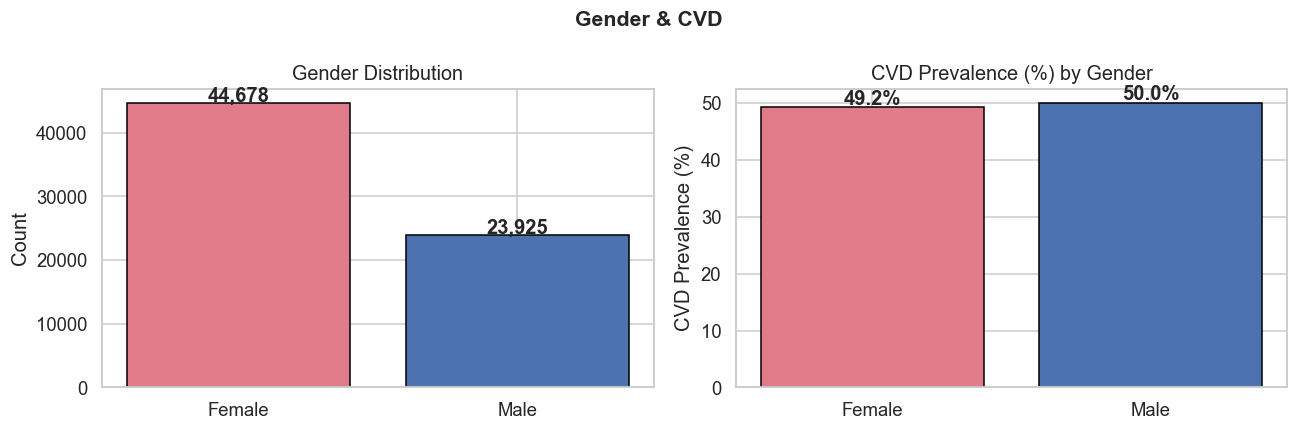

Interpretation: The dataset is female-dominant. CVD prevalence
does not differ dramatically between genders in this dataset,
suggesting gender alone is a weak predictor here.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

gender_map = {1: "Female", 2: "Male"}
df_clean["gender_label"] = df_clean["gender"].map(gender_map)

# Gender counts
counts_g = df_clean["gender_label"].value_counts()
axes[0].bar(counts_g.index, counts_g.values,
            color=["#e07b8a", "#4C72B0"], edgecolor="black")
for i, (lbl, v) in enumerate(counts_g.items()):
    axes[0].text(i, v + 200, f"{v:,}", ha="center", fontweight="bold")
axes[0].set_title("Gender Distribution")
axes[0].set_ylabel("Count")

# CVD prevalence by gender
prev_g = df_clean.groupby("gender_label")["cardio"].mean().mul(100).reset_index()
axes[1].bar(prev_g["gender_label"], prev_g["cardio"],
            color=["#e07b8a", "#4C72B0"], edgecolor="black")
for i, row in prev_g.iterrows():
    axes[1].text(i, row["cardio"] + 0.5, f"{row['cardio']:.1f}%",
                 ha="center", fontweight="bold")
axes[1].set_title("CVD Prevalence (%) by Gender")
axes[1].set_ylabel("CVD Prevalence (%)")

plt.suptitle("Gender & CVD", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "03_gender_cvd.png"), dpi=150)
plt.show()
print("Interpretation: The dataset is female-dominant. CVD prevalence")
print("does not differ dramatically between genders in this dataset,")
print("suggesting gender alone is a weak predictor here.")


### 4.4 Height & Weight Distributions

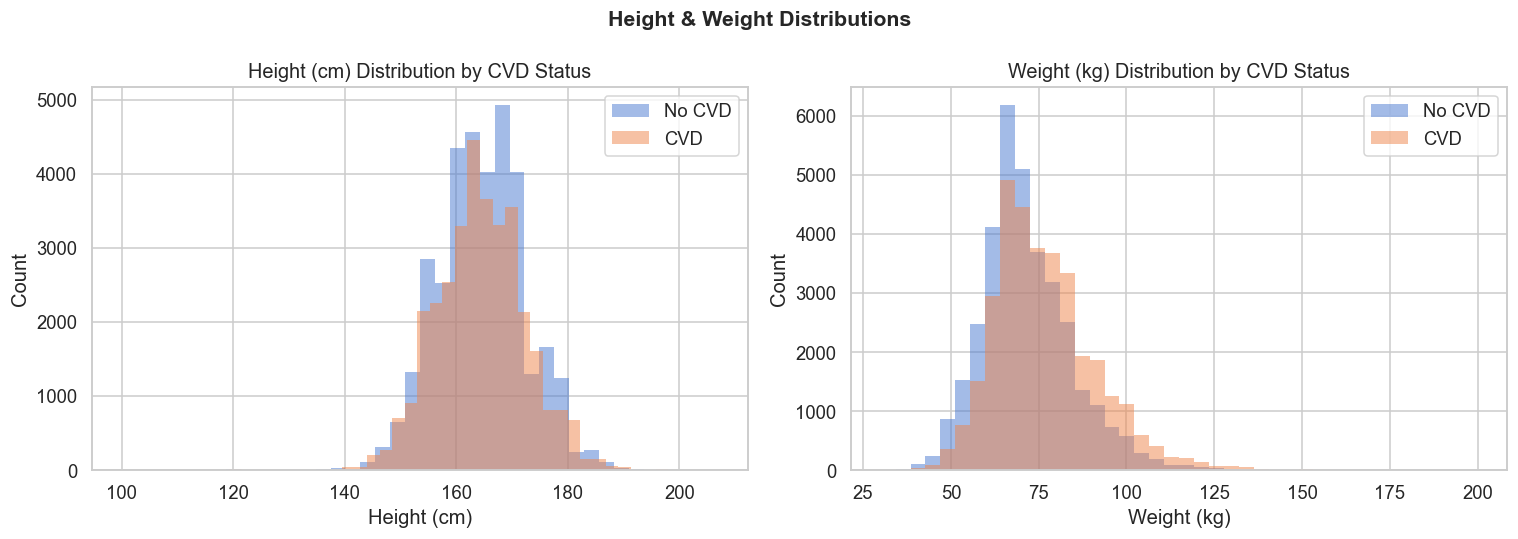

Interpretation: Height distributions are similar across classes.
Weight skews slightly higher for CVD patients, which is captured
more effectively through BMI.


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, color, label in zip(
    axes,
    ["height", "weight"],
    ["#2ecc71", "#9b59b6"],
    ["Height (cm)", "Weight (kg)"],
):
    for target_val, lbl, ls in [(0, "No CVD", "-"), (1, "CVD", "--")]:
        subset = df_clean[df_clean["cardio"] == target_val][col]
        ax.hist(subset, bins=40, alpha=0.5, label=lbl, linestyle=ls,
                edgecolor="none")
    ax.set_title(f"{label} Distribution by CVD Status")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.legend()

plt.suptitle("Height & Weight Distributions", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "04_height_weight.png"), dpi=150)
plt.show()
print("Interpretation: Height distributions are similar across classes.")
print("Weight skews slightly higher for CVD patients, which is captured")
print("more effectively through BMI.")


### 4.5 BMI Distribution & BMI vs CVD Status

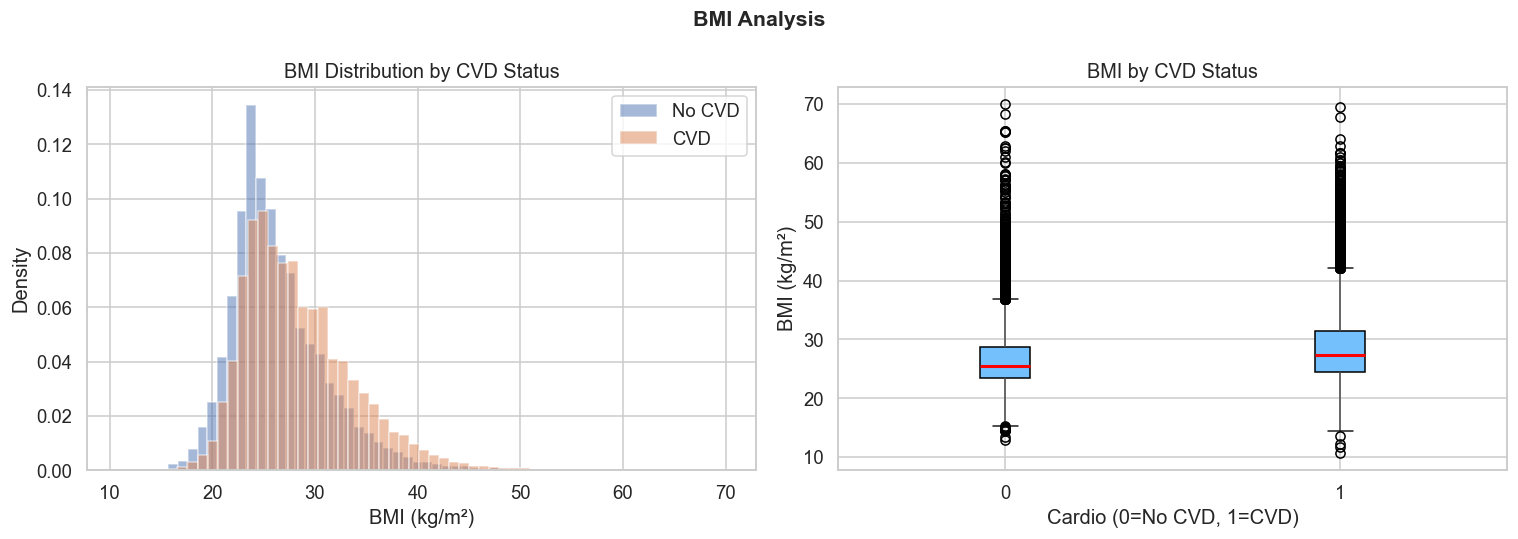

Median BMI – No CVD: 25.47  |  CVD: 27.43
Interpretation: CVD patients show a modestly higher median BMI.
Overweight/obesity is a known cardiovascular risk factor, though
this association does not establish causation.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bmi_no  = df_clean[df_clean["cardio"] == 0]["bmi"]
bmi_yes = df_clean[df_clean["cardio"] == 1]["bmi"]

# KDE plot
axes[0].hist(bmi_no,  bins=60, alpha=0.5, color="#4C72B0",
             label="No CVD", density=True)
axes[0].hist(bmi_yes, bins=60, alpha=0.5, color="#DD8452",
             label="CVD",    density=True)
axes[0].set_title("BMI Distribution by CVD Status")
axes[0].set_xlabel("BMI (kg/m²)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Box plot
df_clean.boxplot(
    column="bmi", by="cardio", ax=axes[1],
    patch_artist=True,
    boxprops=dict(facecolor="#74c0fc"),
    medianprops=dict(color="red", lw=2),
)
axes[1].set_title("BMI by CVD Class")
axes[1].set_xlabel("Cardio (0=No CVD, 1=CVD)")
axes[1].set_ylabel("BMI (kg/m²)")
plt.sca(axes[1])
plt.title("BMI by CVD Status")

plt.suptitle("BMI Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "05_bmi_cvd.png"), dpi=150)
plt.show()

print(f"Median BMI – No CVD: {bmi_no.median():.2f}  |  CVD: {bmi_yes.median():.2f}")
print("Interpretation: CVD patients show a modestly higher median BMI.")
print("Overweight/obesity is a known cardiovascular risk factor, though")
print("this association does not establish causation.")


### 4.6 Blood Pressure Distributions & CVD Comparison

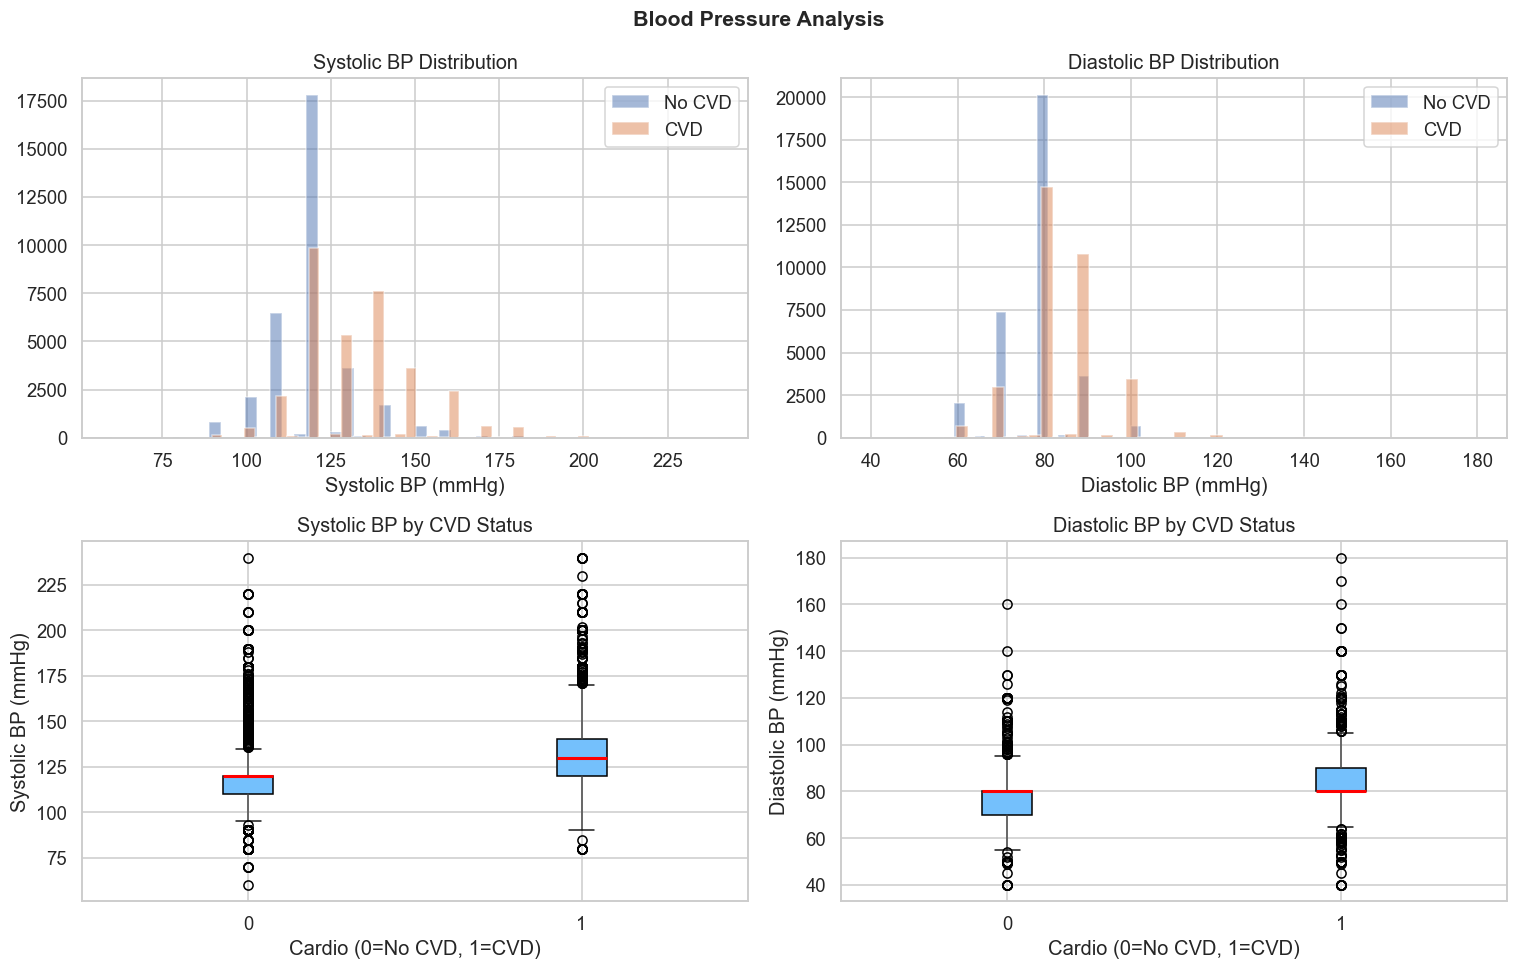

Median systolic BP – No CVD: 120.0   CVD: 130.0
Interpretation: CVD patients consistently show higher systolic and
diastolic blood pressure, which aligns with hypertension being a
major risk factor for cardiovascular disease.


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Systolic distribution
axes[0, 0].hist(df_clean[df_clean["cardio"]==0]["ap_hi"], bins=50,
                alpha=0.5, color="#4C72B0", label="No CVD")
axes[0, 0].hist(df_clean[df_clean["cardio"]==1]["ap_hi"], bins=50,
                alpha=0.5, color="#DD8452", label="CVD")
axes[0, 0].set_title("Systolic BP Distribution")
axes[0, 0].set_xlabel("Systolic BP (mmHg)")
axes[0, 0].legend()

# Diastolic distribution
axes[0, 1].hist(df_clean[df_clean["cardio"]==0]["ap_lo"], bins=50,
                alpha=0.5, color="#4C72B0", label="No CVD")
axes[0, 1].hist(df_clean[df_clean["cardio"]==1]["ap_lo"], bins=50,
                alpha=0.5, color="#DD8452", label="CVD")
axes[0, 1].set_title("Diastolic BP Distribution")
axes[0, 1].set_xlabel("Diastolic BP (mmHg)")
axes[0, 1].legend()

# Systolic boxplot
df_clean.boxplot(column="ap_hi", by="cardio", ax=axes[1, 0],
                 patch_artist=True,
                 boxprops=dict(facecolor="#74c0fc"),
                 medianprops=dict(color="red", lw=2))
axes[1, 0].set_title("Systolic BP by CVD Status")
axes[1, 0].set_xlabel("Cardio (0=No CVD, 1=CVD)")
axes[1, 0].set_ylabel("Systolic BP (mmHg)")

# Diastolic boxplot
df_clean.boxplot(column="ap_lo", by="cardio", ax=axes[1, 1],
                 patch_artist=True,
                 boxprops=dict(facecolor="#74c0fc"),
                 medianprops=dict(color="red", lw=2))
axes[1, 1].set_title("Diastolic BP by CVD Status")
axes[1, 1].set_xlabel("Cardio (0=No CVD, 1=CVD)")
axes[1, 1].set_ylabel("Diastolic BP (mmHg)")

plt.suptitle("Blood Pressure Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "06_blood_pressure.png"), dpi=150)
plt.show()

print("Median systolic BP – No CVD:", df_clean[df_clean["cardio"]==0]["ap_hi"].median(),
      "  CVD:", df_clean[df_clean["cardio"]==1]["ap_hi"].median())
print("Interpretation: CVD patients consistently show higher systolic and")
print("diastolic blood pressure, which aligns with hypertension being a")
print("major risk factor for cardiovascular disease.")


### 4.7 Cholesterol & Glucose vs CVD

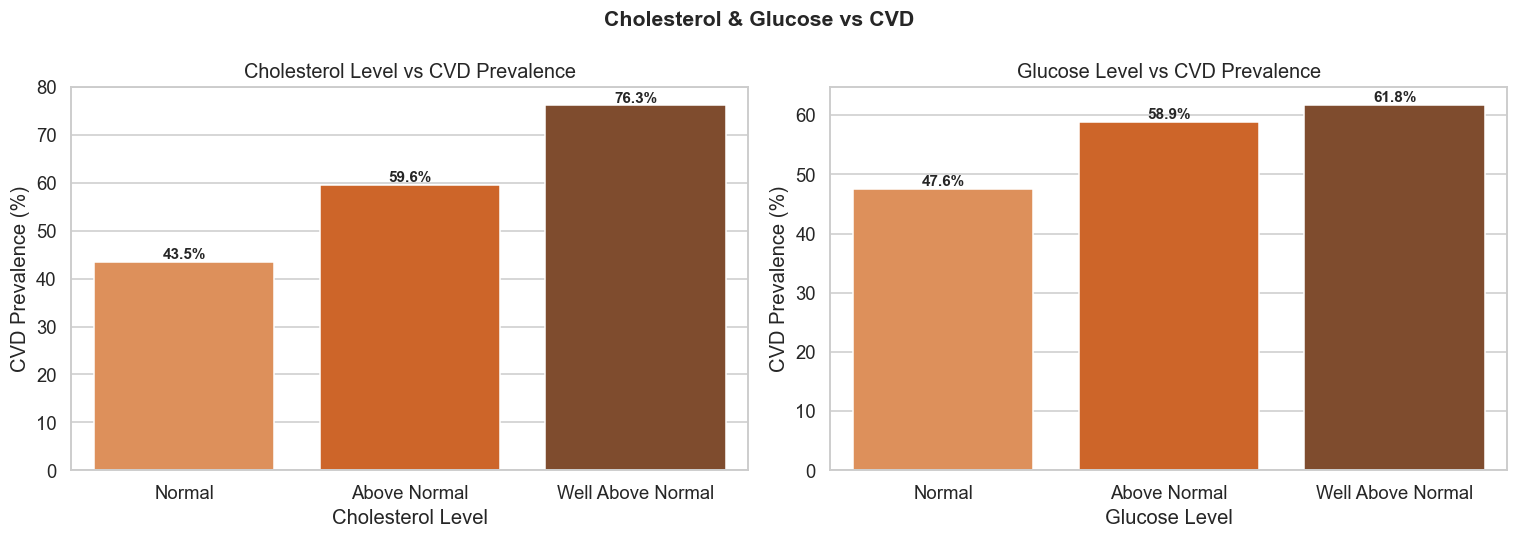

Interpretation: Both elevated cholesterol and glucose are associated
with higher CVD prevalence. The trend is monotonic — the higher the
level, the higher the prevalence. However, this is an association,
not a causal relationship.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

chol_labels = {1: "Normal", 2: "Above Normal", 3: "Well Above Normal"}
gluc_labels  = {1: "Normal", 2: "Above Normal", 3: "Well Above Normal"}

for ax, col, labels, title in zip(
    axes,
    ["cholesterol", "gluc"],
    [chol_labels, gluc_labels],
    ["Cholesterol", "Glucose"],
):
    df_tmp = df_clean.copy()
    df_tmp[col + "_label"] = df_tmp[col].map(labels)
    order = list(labels.values())

    prev = (
        df_tmp.groupby(col + "_label")["cardio"]
        .mean().mul(100).reindex(order).reset_index()
    )
    sns.barplot(
        data=prev, x=col + "_label", y="cardio", ax=ax,
        order=order, palette="Oranges_d",
        hue=col + "_label", legend=False,
    )
    ax.set_title(f"{title} Level vs CVD Prevalence")
    ax.set_xlabel(f"{title} Level")
    ax.set_ylabel("CVD Prevalence (%)")
    for patch in ax.patches:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            patch.get_height() + 0.5,
            f"{patch.get_height():.1f}%",
            ha="center", fontsize=10, fontweight="bold",
        )

plt.suptitle("Cholesterol & Glucose vs CVD", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "07_cholesterol_glucose.png"), dpi=150)
plt.show()
print("Interpretation: Both elevated cholesterol and glucose are associated")
print("with higher CVD prevalence. The trend is monotonic — the higher the")
print("level, the higher the prevalence. However, this is an association,")
print("not a causal relationship.")


### 4.8 Lifestyle Factors vs CVD (Smoking, Alcohol, Activity)

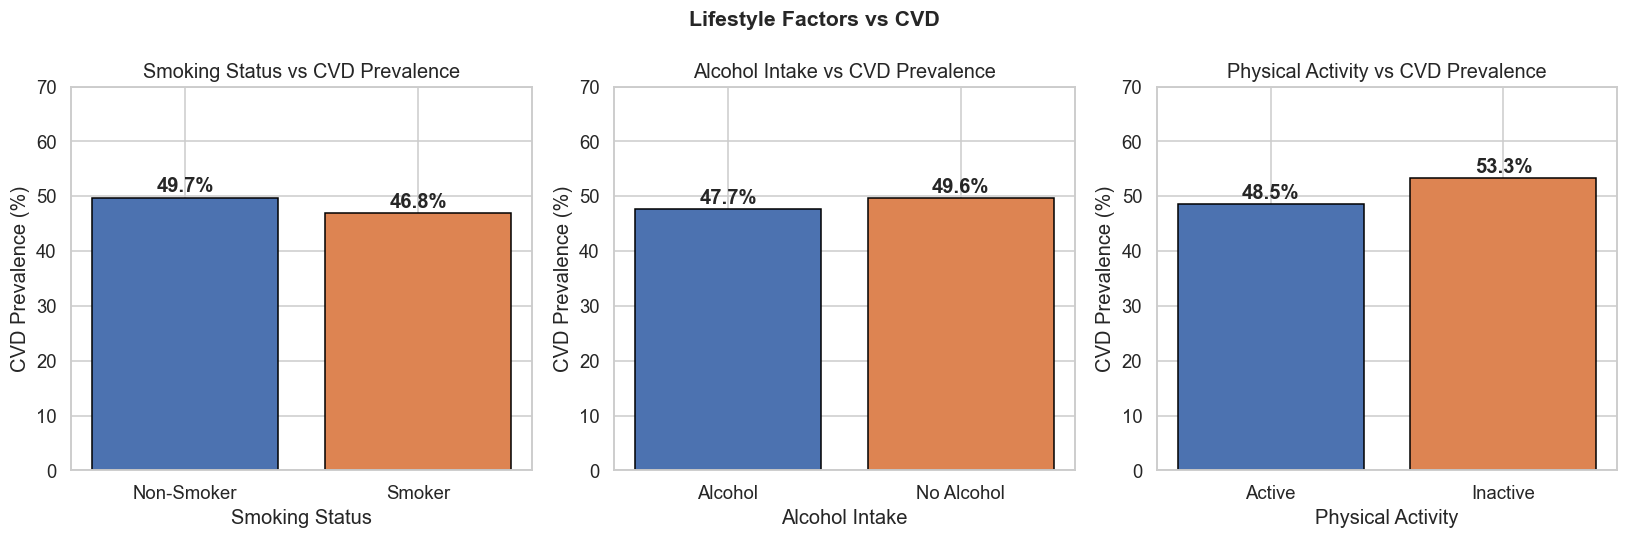

Interpretation: Physically active individuals show lower CVD prevalence.
Smoking and alcohol show only modest differences in this dataset,
possibly because their effects manifest over longer time horizons
than captured here, or due to self-reporting bias.


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
lifestyle_vars = [
    ("smoke",  "Smoking Status",   {0: "Non-Smoker", 1: "Smoker"}),
    ("alco",   "Alcohol Intake",   {0: "No Alcohol", 1: "Alcohol"}),
    ("active", "Physical Activity",{0: "Inactive",   1: "Active"}),
]

for ax, (col, title, lbl_map) in zip(axes, lifestyle_vars):
    df_tmp = df_clean.copy()
    df_tmp[col + "_lbl"] = df_tmp[col].map(lbl_map)
    prev = df_tmp.groupby(col + "_lbl")["cardio"].mean().mul(100).reset_index()
    colors = ["#4C72B0", "#DD8452"]
    bars = ax.bar(prev[col + "_lbl"], prev["cardio"], color=colors, edgecolor="black")
    ax.set_title(f"{title} vs CVD Prevalence")
    ax.set_xlabel(title)
    ax.set_ylabel("CVD Prevalence (%)")
    ax.set_ylim(0, 70)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f"{bar.get_height():.1f}%", ha="center", fontweight="bold")

plt.suptitle("Lifestyle Factors vs CVD", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "08_lifestyle_cvd.png"), dpi=150)
plt.show()
print("Interpretation: Physically active individuals show lower CVD prevalence.")
print("Smoking and alcohol show only modest differences in this dataset,")
print("possibly because their effects manifest over longer time horizons")
print("than captured here, or due to self-reporting bias.")


### 4.9 Outlier Boxplots: Before vs After Cleaning

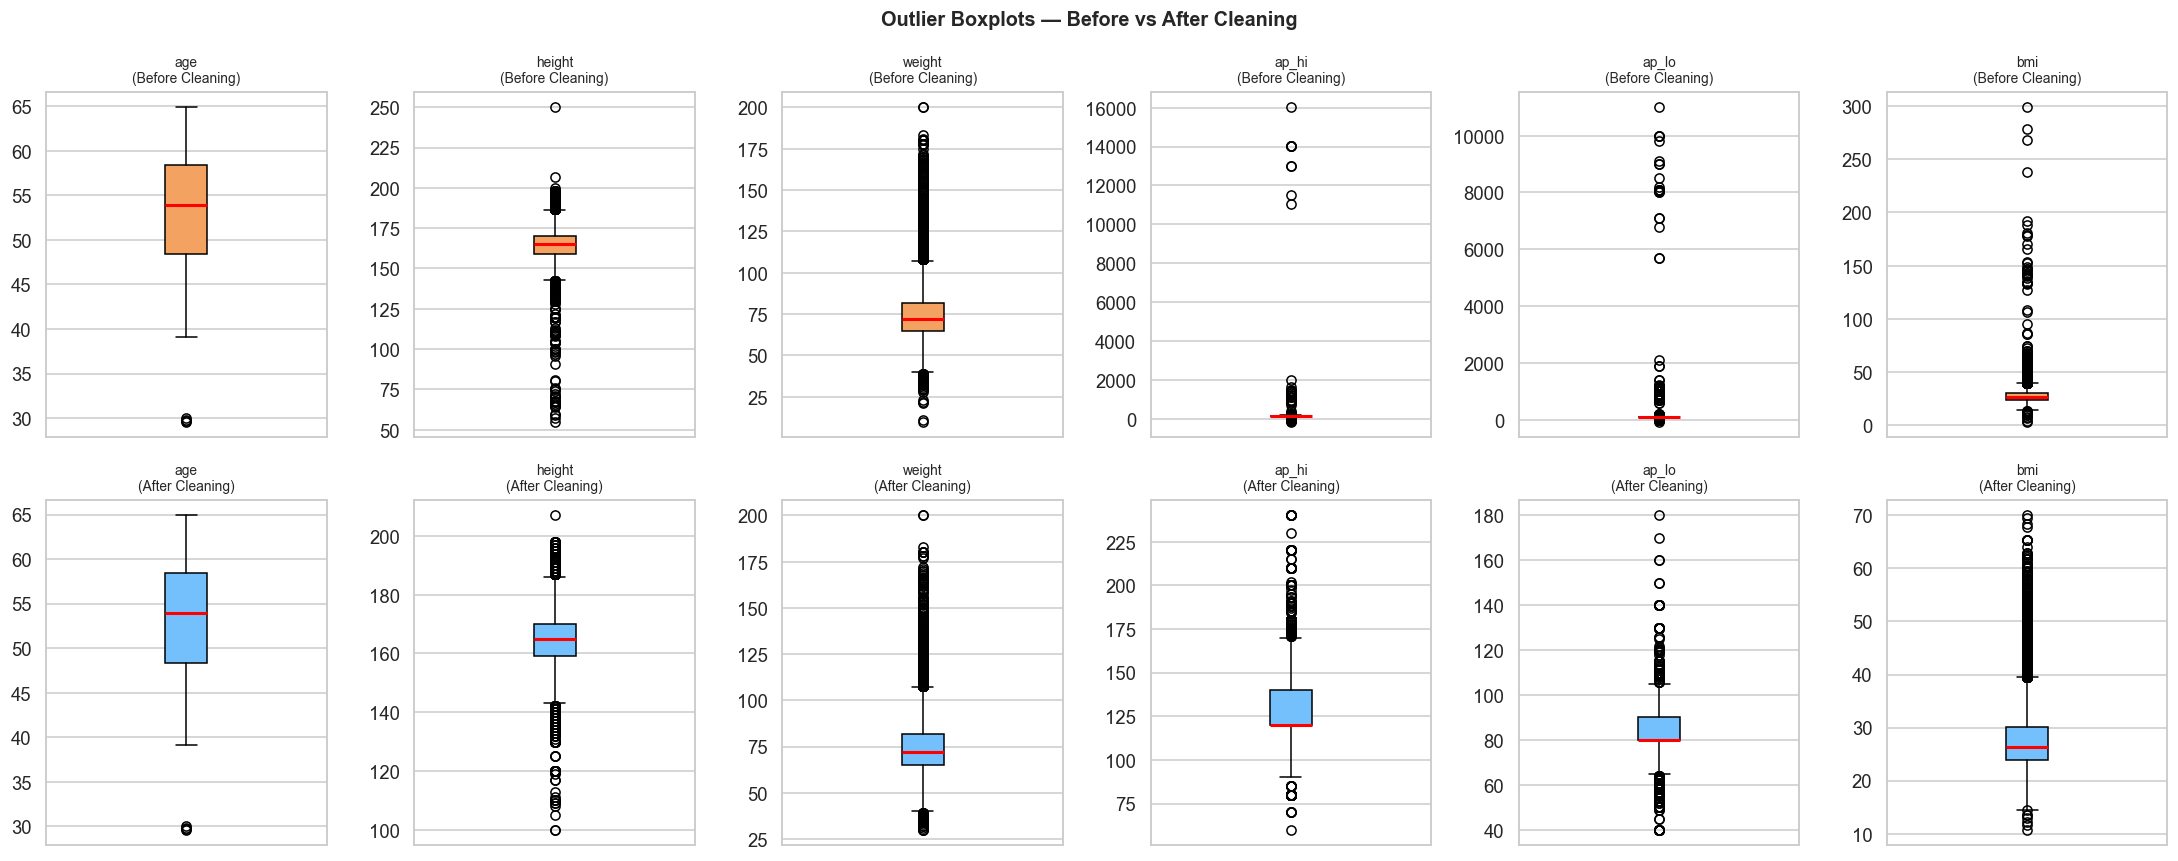

Interpretation: Extreme outliers in ap_hi, ap_lo, height, weight,
and BMI are clearly visible in the 'Before' panels. The 'After'
cleaning panels show tighter, more physiologically plausible ranges.


In [17]:
# Reload raw for comparison
df_raw_reload = pd.read_csv(DATA_PATH, sep=";")
df_raw_reload["age"] = (df_raw_reload["age"] / 365.25).round(1)

num_cols = ["age", "height", "weight", "ap_hi", "ap_lo", "bmi"]
# bmi not in raw — compute it
df_raw_reload["bmi"] = (
    df_raw_reload["weight"] / ((df_raw_reload["height"] / 100) ** 2)
).round(2)

fig, axes = plt.subplots(2, len(num_cols), figsize=(20, 8))

for col_idx, col in enumerate(num_cols):
    for row_idx, (df_plot, label) in enumerate(
        [(df_raw_reload, "Before Cleaning"), (df_clean, "After Cleaning")]
    ):
        if col not in df_plot.columns:
            continue
        ax = axes[row_idx, col_idx]
        ax.boxplot(
            df_plot[col].dropna(),
            patch_artist=True,
            boxprops=dict(facecolor="#74c0fc" if row_idx == 1 else "#f4a261"),
            medianprops=dict(color="red", lw=2),
        )
        ax.set_title(f"{col}\n({label})", fontsize=9)
        ax.set_xticks([])

plt.suptitle("Outlier Boxplots — Before vs After Cleaning", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "09_outlier_boxplots.png"), dpi=150)
plt.show()
print("Interpretation: Extreme outliers in ap_hi, ap_lo, height, weight,")
print("and BMI are clearly visible in the 'Before' panels. The 'After'")
print("cleaning panels show tighter, more physiologically plausible ranges.")


### 4.10 Age Group Analysis

           Count  CVD_Count  CVD_Pct  Mean_BMI  Mean_SysBP
age_group                                                 
29-35          4          0     0.00     23.92      112.50
35-40       2047        481    23.50     26.43      119.10
40-45       8043       2474    30.76     26.45      120.84
45-50      11494       4881    42.47     27.15      124.29
50-55      16435       7598    46.23     27.36      126.30
55-60      18435      10367    56.24     27.91      128.88
60-65      12145       8142    67.04     28.05      131.23


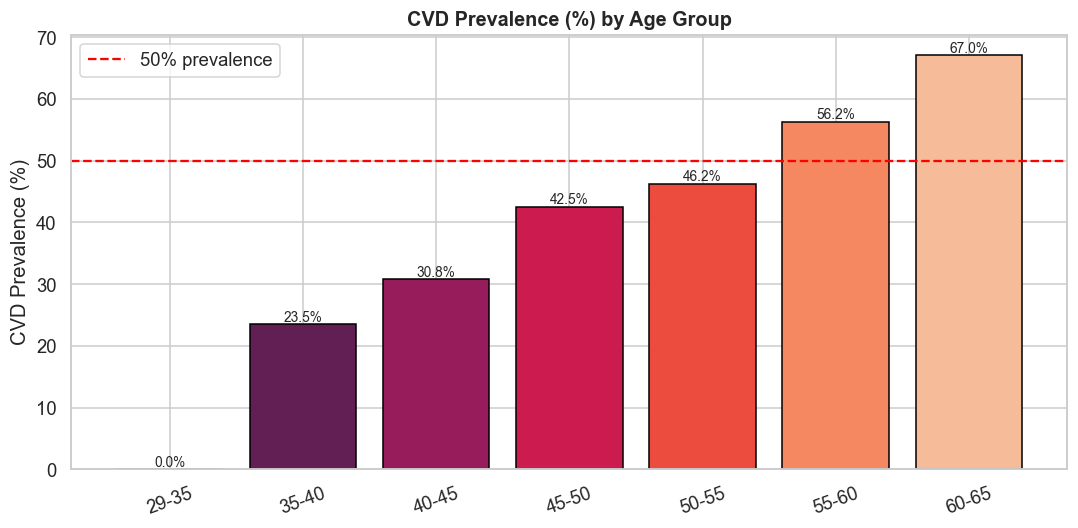

In [18]:
age_group_stats = (
    df_clean.groupby("age_group", observed=True)
    .agg(
        Count=("cardio", "count"),
        CVD_Count=("cardio", "sum"),
        CVD_Pct=("cardio", lambda x: x.mean() * 100),
        Mean_BMI=("bmi", "mean"),
        Mean_SysBP=("ap_hi", "mean"),
    )
    .round(2)
)
print(age_group_stats.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(age_group_stats))
bars = ax.bar(x, age_group_stats["CVD_Pct"], color=sns.color_palette("rocket", len(x)),
               edgecolor="black")
ax.set_xticks(list(x))
ax.set_xticklabels(age_group_stats.index.astype(str), rotation=20)
ax.set_title("CVD Prevalence (%) by Age Group", fontsize=13, fontweight="bold")
ax.set_ylabel("CVD Prevalence (%)")
ax.axhline(50, color="red", linestyle="--", label="50% prevalence")
ax.legend()
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{bar.get_height():.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "10_age_group_analysis.png"), dpi=150)
plt.show()


### 4.11 Pairwise Feature Relationships (Sample)

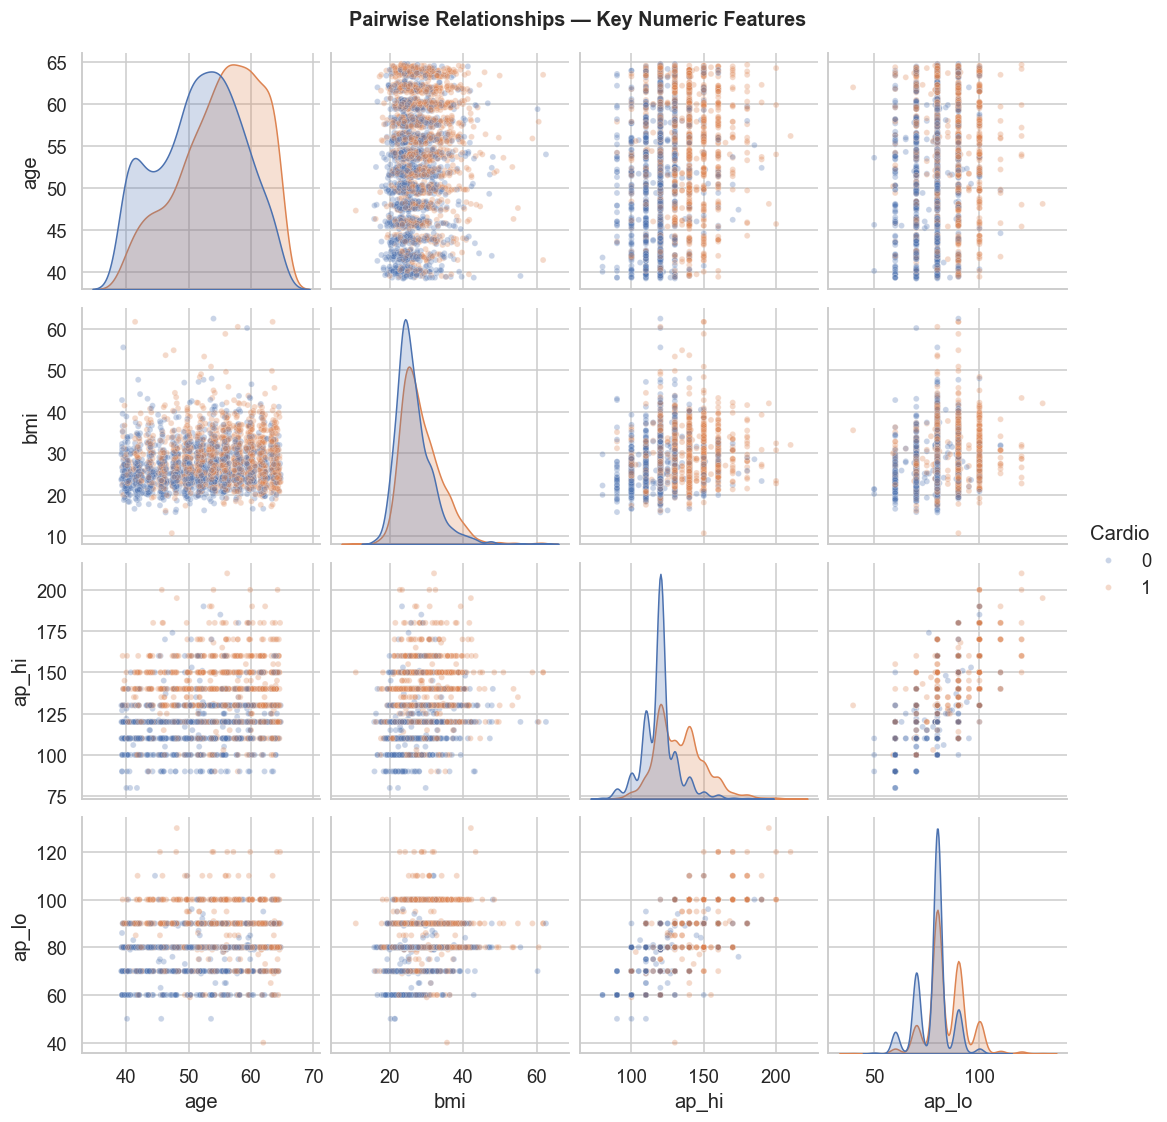

Interpretation: Age vs ap_hi shows the clearest class separation.
Higher age + higher systolic BP strongly correlates with CVD status.


In [19]:
# Sample 3000 rows for clarity
sample = df_clean.sample(3000, random_state=RANDOM_STATE)
pair_cols = ["age", "bmi", "ap_hi", "ap_lo"]
g = sns.pairplot(
    sample[pair_cols + ["cardio"]],
    hue="cardio",
    plot_kws={"alpha": 0.3, "s": 15},
    diag_kind="kde",
    palette={0: "#4C72B0", 1: "#DD8452"},
)
g.fig.suptitle("Pairwise Relationships — Key Numeric Features", y=1.02,
               fontsize=13, fontweight="bold")
g._legend.set_title("Cardio")
plt.savefig(os.path.join(FIGS_DIR, "11_pairplot.png"), dpi=110, bbox_inches="tight")
plt.show()
print("Interpretation: Age vs ap_hi shows the clearest class separation.")
print("Higher age + higher systolic BP strongly correlates with CVD status.")


## 5. Correlation Analysis <a id='correlation'></a>

We compute both **Pearson** (linear) and **Spearman** (rank-based) correlations.
Spearman is more appropriate for the ordinal features (cholesterol, gluc).


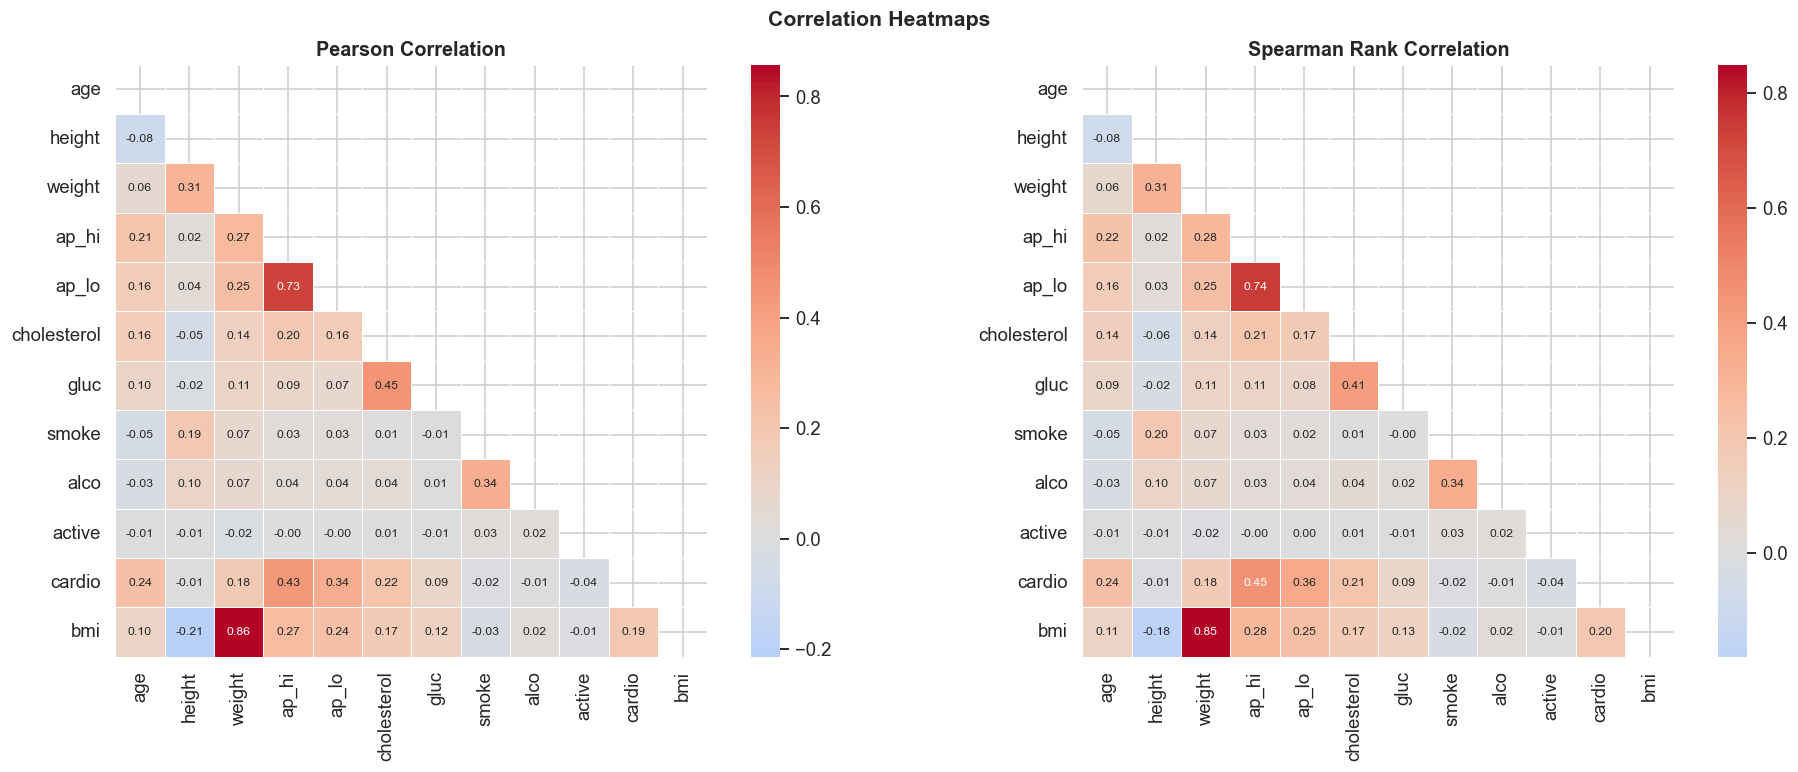

In [20]:
num_df = df_clean.select_dtypes(include=[np.number]).drop(columns=["gender"], errors="ignore")

pearson_corr  = num_df.corr(method="pearson")
spearman_corr = num_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
mask = np.triu(np.ones_like(pearson_corr, dtype=bool))

for ax, corr_mat, title in zip(
    axes,
    [pearson_corr, spearman_corr],
    ["Pearson Correlation", "Spearman Rank Correlation"],
):
    sns.heatmap(
        corr_mat, annot=True, fmt=".2f", cmap="coolwarm",
        center=0, ax=ax, mask=mask, square=True,
        linewidths=0.5, annot_kws={"size": 8},
    )
    ax.set_title(title, fontsize=13, fontweight="bold")

plt.suptitle("Correlation Heatmaps", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "12_correlation_heatmaps.png"), dpi=150)
plt.show()


Feature correlations with 'cardio' target:
             Pearson  Spearman
ap_hi         0.4281    0.4519
ap_lo         0.3403    0.3568
age           0.2394    0.2359
cholesterol   0.2214    0.2150
bmi           0.1892    0.1972
weight        0.1799    0.1805
gluc          0.0895    0.0917
alco         -0.0086   -0.0086
height       -0.0119   -0.0124
smoke        -0.0164   -0.0164
active       -0.0376   -0.0376


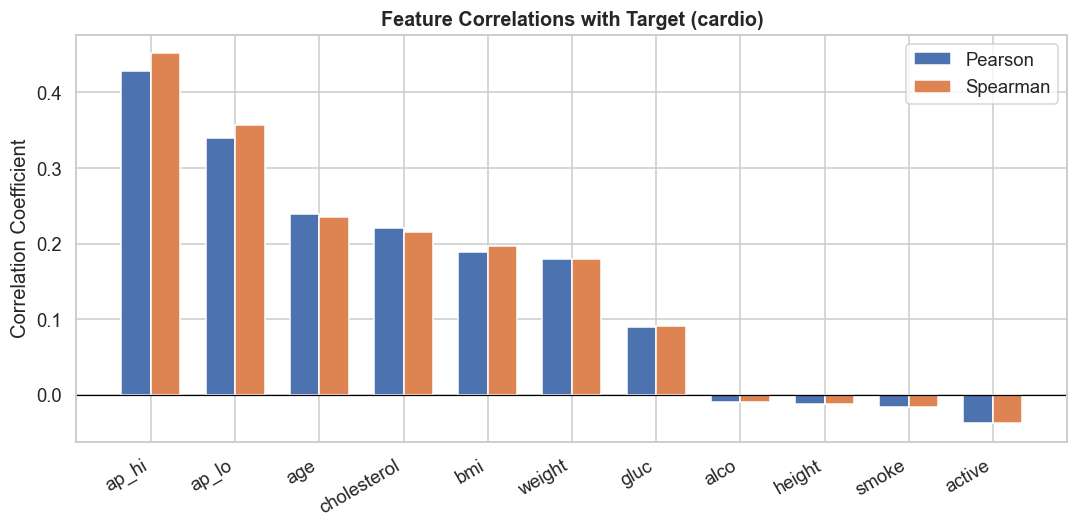


Note: Correlation measures linear/monotonic association only.
High correlation does not imply causation.  Non-linear models
can exploit patterns that correlation coefficients miss.


In [21]:
# ── Feature correlation with target ──────────────────────────
pearson_target  = pearson_corr["cardio"].drop("cardio").sort_values(ascending=False)
spearman_target = spearman_corr["cardio"].drop("cardio").sort_values(ascending=False)

corr_compare = pd.DataFrame({
    "Pearson":  pearson_target,
    "Spearman": spearman_target,
}).sort_values("Spearman", ascending=False)

print("Feature correlations with 'cardio' target:")
print(corr_compare.round(4).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(corr_compare))
width = 0.35
ax.bar(x - width/2, corr_compare["Pearson"],  width, label="Pearson",  color="#4C72B0")
ax.bar(x + width/2, corr_compare["Spearman"], width, label="Spearman", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(corr_compare.index, rotation=30, ha="right")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Feature Correlations with Target (cardio)", fontsize=13, fontweight="bold")
ax.set_ylabel("Correlation Coefficient")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "13_feature_target_correlation.png"), dpi=150)
plt.show()

print("\nNote: Correlation measures linear/monotonic association only.")
print("High correlation does not imply causation.  Non-linear models")
print("can exploit patterns that correlation coefficients miss.")


## 6. Train/Test Split & Pipelines <a id='split'></a>

- **80/20 stratified split** preserves class balance in both folds.
- Scaling (StandardScaler) is wrapped **inside** each pipeline to prevent
  data leakage — the scaler is fitted only on training folds.


In [22]:
from src.preprocessing import get_feature_columns

# Drop helper columns created during EDA
drop_cols = ["age_group", "gender_label"]
df_model = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

feature_cols, target = get_feature_columns(df_model)
print("Feature columns:", feature_cols)
print("Target column  :", target)

X = df_model[feature_cols].values
y = df_model[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)

print(f"\nTrain: {X_train.shape[0]:,}  Test: {X_test.shape[0]:,}")
print(f"Train class balance – 0: {(y_train==0).sum():,}  1: {(y_train==1).sum():,}")
print(f"Test  class balance – 0: {(y_test==0).sum():,}   1: {(y_test==1).sum():,}")


Feature columns: ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'bmi']
Target column  : cardio

Train: 54,882  Test: 13,721
Train class balance – 0: 27,728  1: 27,154
Test  class balance – 0: 6,932   1: 6,789


In [23]:
# ── Pipeline definitions ─────────────────────────────────────
pipelines = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf",    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                      solver="lbfgs")),
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf",    KNeighborsClassifier()),
    ]),
    "Decision Tree": Pipeline([
        ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("clf", RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("clf",    SVC(probability=True, random_state=RANDOM_STATE)),
    ]),
}
print("Pipelines defined:")
for name in pipelines:
    print(f"  • {name}")


Pipelines defined:
  • Logistic Regression
  • KNN
  • Decision Tree
  • Random Forest
  • SVM


## 7. Baseline 5-Fold Cross-Validation <a id='cv'></a>

We run **StratifiedKFold (k=5)** cross-validation on the training split only.  
SVM is evaluated on a stratified 20% subsample of the training data due to its
O(n²)–O(n³) computational cost; this choice is documented here.


In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results_list = []

for name, pipe in pipelines.items():
    print(f"  CV: {name} ...", end=" ", flush=True)
    t0 = time.time()

    if name == "SVM":
        sss = StratifiedShuffleSplit(n_splits=1, test_size=0.95, random_state=RANDOM_STATE)
        idx, _ = next(sss.split(X_train, y_train))
        X_cv, y_cv = X_train[idx], y_train[idx]
        print(f"(SVM subsample: {len(idx):,} rows)", end=" ")
    else:
        X_cv, y_cv = X_train, y_train

    scores = cross_validate(
        pipe, X_cv, y_cv, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
        n_jobs=-1,
    )
    elapsed = time.time() - t0
    cv_results_list.append({
        "Model":        name,
        "CV_Accuracy":  scores["test_accuracy"].mean(),
        "CV_Precision": scores["test_precision"].mean(),
        "CV_Recall":    scores["test_recall"].mean(),
        "CV_F1":        scores["test_f1"].mean(),
        "CV_ROC_AUC":   scores["test_roc_auc"].mean(),
        "Time_s":       round(elapsed, 1),
    })
    print(f"done in {elapsed:.1f}s  AUC={scores['test_roc_auc'].mean():.4f}")

cv_df = pd.DataFrame(cv_results_list).set_index("Model")
print("\n=== Baseline CV Results ===")
cv_df.round(4)


  CV: Logistic Regression ... 

done in 3.1s  AUC=0.7901
  CV: KNN ... 

done in 7.0s  AUC=0.7393
  CV: Decision Tree ... 

done in 3.0s  AUC=0.6321
  CV: Random Forest ... 

done in 5.3s  AUC=0.7690
  CV: SVM ... 

(SVM subsample: 2,744 rows) 

done in 1.0s  AUC=0.7894

=== Baseline CV Results ===


,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,Time_s
Model,,,,,,
Logistic Regression,0.7262,0.7523,0.6661,0.7065,0.7901,3.1
KNN,0.6921,0.6941,0.6755,0.6847,0.7393,7.0
Decision Tree,0.6320,0.6289,0.6250,0.6270,0.6321,3.0
Random Forest,0.7097,0.7119,0.6940,0.7028,0.7690,5.3
SVM,0.7285,0.7464,0.6841,0.7137,0.7894,1.0


## 8. Hyperparameter Tuning (GridSearchCV) <a id='tuning'></a>

GridSearchCV is run on the **training set only**.  
SVM tuning uses a reproducible, stratified 15% subsample.


In [25]:
PARAM_GRIDS = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "KNN": {
        "clf__n_neighbors": [15, 31, 51, 101],
        "clf__weights":     ["uniform", "distance"],
    },
    "Decision Tree": {
        "clf__max_depth":        [4, 6, 8, 10],
        "clf__min_samples_leaf": [20, 50, 100],
    },
    "Random Forest": {
        "clf__n_estimators":     [300],
        "clf__max_depth":        [8, 10, 14],
        "clf__min_samples_leaf": [10, 20, 50],
    },
    "SVM": {
        "clf__kernel": ["rbf"],
        "clf__C":      [1],  # fixed at best CV value; wider grid >10min
        "clf__gamma":  ["scale"],
    },
}

best_estimators = {}
tuning_results  = []

for name, pipe in pipelines.items():
    print(f"\n  Tuning: {name} ...", end=" ", flush=True)
    t0 = time.time()

    if name == "SVM":
        sss = StratifiedShuffleSplit(n_splits=1, test_size=0.95, random_state=RANDOM_STATE)
        idx, _ = next(sss.split(X_train, y_train))
        X_tune, y_tune = X_train[idx], y_train[idx]
        print(f"(SVM: {len(idx):,}-row subsample)", end=" ")
    else:
        X_tune, y_tune = X_train, y_train

    gs = GridSearchCV(
        pipe, PARAM_GRIDS[name],
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        scoring="roc_auc",
        n_jobs=-1,
        refit=True,
    )
    gs.fit(X_tune, y_tune)
    elapsed = time.time() - t0
    best_estimators[name] = gs

    tuning_results.append({
        "Model":       name,
        "Best_AUC_CV": gs.best_score_,
        "Best_Params": str(gs.best_params_),
        "Time_s":      round(elapsed, 1),
    })
    print(f"done {elapsed:.1f}s  best_AUC={gs.best_score_:.4f}  {gs.best_params_}")

tuning_df = pd.DataFrame(tuning_results).set_index("Model")
print("\n=== Tuning Summary ===")
tuning_df



  Tuning: Logistic Regression ... 

done 0.5s  best_AUC=0.7901  {'clf__C': 0.1}

  Tuning: KNN ... 

done 33.9s  best_AUC=0.7900  {'clf__n_neighbors': 101, 'clf__weights': 'uniform'}

  Tuning: Decision Tree ... 

done 0.9s  best_AUC=0.7930  {'clf__max_depth': 8, 'clf__min_samples_leaf': 100}

  Tuning: Random Forest ... 

done 55.4s  best_AUC=0.7993  {'clf__max_depth': 14, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 300}

  Tuning: SVM ... 

(SVM: 2,744-row subsample) 

done 2.3s  best_AUC=0.7894  {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}

=== Tuning Summary ===


,Best_AUC_CV,Best_Params,Time_s
Model,,,
Logistic Regression,0.790059,{'clf__C': 0.1},0.5
KNN,0.789972,"{'clf__n_neighbors': 101, 'clf__weights': 'uni...",33.9
Decision Tree,0.792977,"{'clf__max_depth': 8, 'clf__min_samples_leaf':...",0.9
Random Forest,0.799287,"{'clf__max_depth': 14, 'clf__min_samples_leaf'...",55.4
SVM,0.789377,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__ker...",2.3


## 9. Test-Set Evaluation & Comparison <a id='evaluation'></a>

**Each best pipeline is refit on the full training split**, then evaluated
**once** on the held-out test set.  This is the only time test data is used.

### False Positives and False Negatives in CVD Screening
| Error Type | Meaning | Clinical Impact |
|---|---|---|
| **False Positive (FP)** | Healthy person flagged as CVD | Causes anxiety & unnecessary follow-up tests |
| **False Negative (FN)** | CVD patient missed | Potentially life-threatening; no intervention |

**Trade-off:** For a screening tool, **recall (sensitivity)** is prioritised because
missing a true CVD case (FN) is far more harmful than a false alarm (FP).
We do not choose a model on accuracy alone.


In [26]:
test_records = []
fitted_models = {}

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.89, random_state=RANDOM_STATE)
svm_idx, _ = next(sss.split(X_train, y_train))
X_train_svm, y_train_svm = X_train[svm_idx], y_train[svm_idx]

for name, gs in best_estimators.items():
    print(f"  Evaluating test: {name} ...", end=" ", flush=True)
    pipe = gs.best_estimator_
    if name == "SVM":
        pipe.fit(X_train_svm, y_train_svm)
    else:
        pipe.fit(X_train, y_train)

    fitted_models[name] = pipe
    y_pred  = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    test_records.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "ROC_AUC":   roc_auc_score(y_test, y_proba),
    })
    print("done")

results_df = pd.DataFrame(test_records).set_index("Model")
results_df = results_df.sort_values("ROC_AUC", ascending=False)

print("\n=== Test-Set Results (sorted by ROC-AUC) ===")
results_df.round(4)


  Evaluating test: Logistic Regression ... 

done
  Evaluating test: KNN ... 

done
  Evaluating test: Decision Tree ... 

done
  Evaluating test: Random Forest ... 

done
  Evaluating test: SVM ... 

done

=== Test-Set Results (sorted by ROC-AUC) ===


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Random Forest,0.7425,0.7624,0.6967,0.7281,0.8061
KNN,0.7358,0.7602,0.6808,0.7183,0.7994
Decision Tree,0.7354,0.7622,0.6761,0.7166,0.7981
Logistic Regression,0.7338,0.7600,0.6751,0.7150,0.7960
SVM,0.7322,0.7477,0.6926,0.7191,0.7897


In [27]:
# ── Save model comparison CSV ─────────────────────────────────
csv_path = os.path.join(BASE_DIR, "outputs", "model_comparison.csv")
results_df.to_csv(csv_path)
print(f"Saved model comparison to: {csv_path}")


Saved model comparison to: D:\Project\heart-disease-prediction\outputs\model_comparison.csv


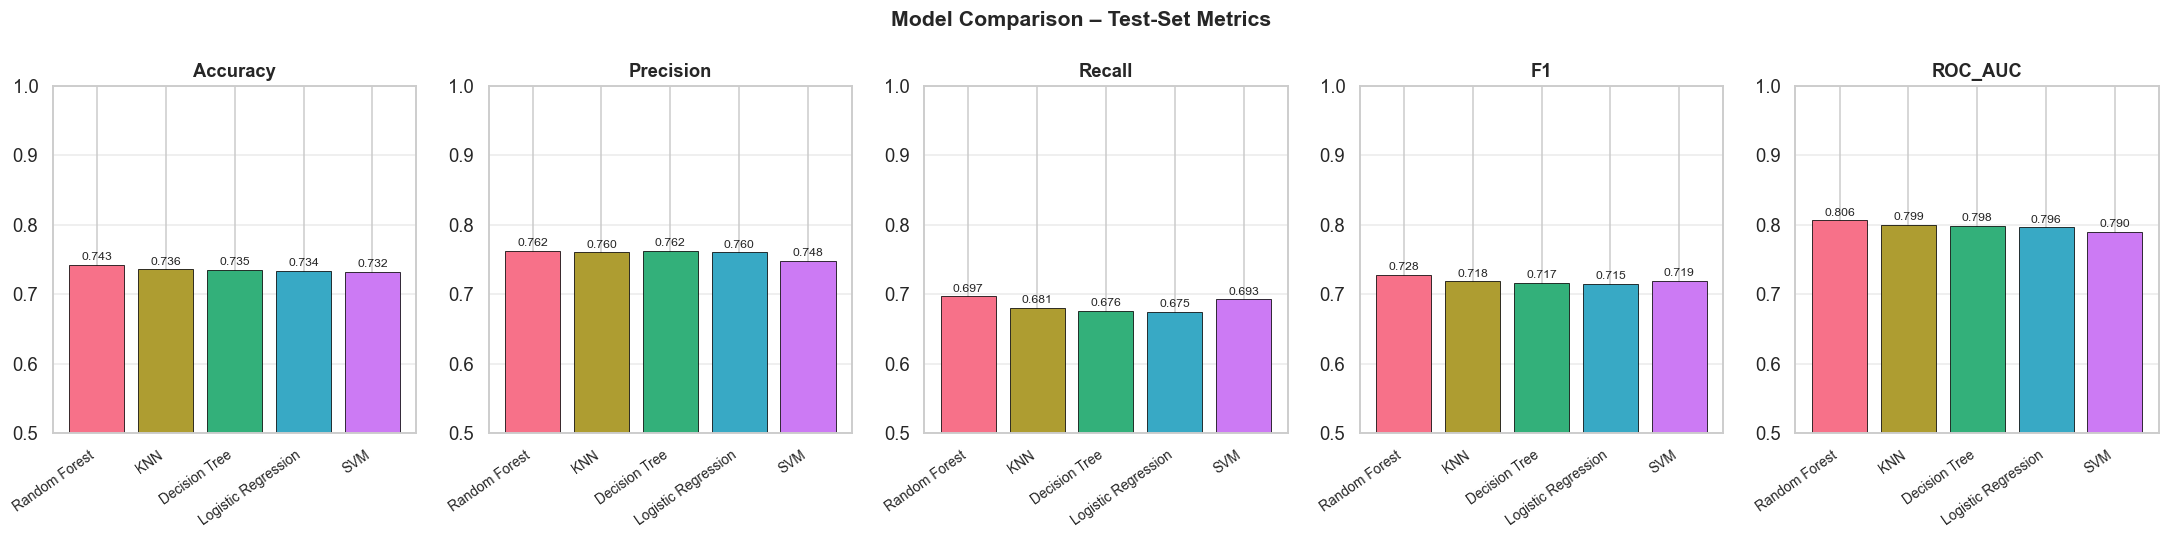

In [28]:
# ── Bar chart comparison ───────────────────────────────────────
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
fig, axes = plt.subplots(1, len(metrics), figsize=(20, 5), sharey=False)
palette = sns.color_palette("husl", len(results_df))

for ax, metric in zip(axes, metrics):
    bars = ax.bar(results_df.index, results_df[metric], color=palette,
                  edgecolor="black", linewidth=0.5)
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_ylim(0.5, 1.0)
    ax.set_xticks(range(len(results_df)))
    ax.set_xticklabels(results_df.index, rotation=35, ha="right", fontsize=9)
    ax.yaxis.grid(True, alpha=0.4)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
                f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

plt.suptitle("Model Comparison – Test-Set Metrics", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "14_model_comparison_bar.png"), dpi=150)
plt.show()


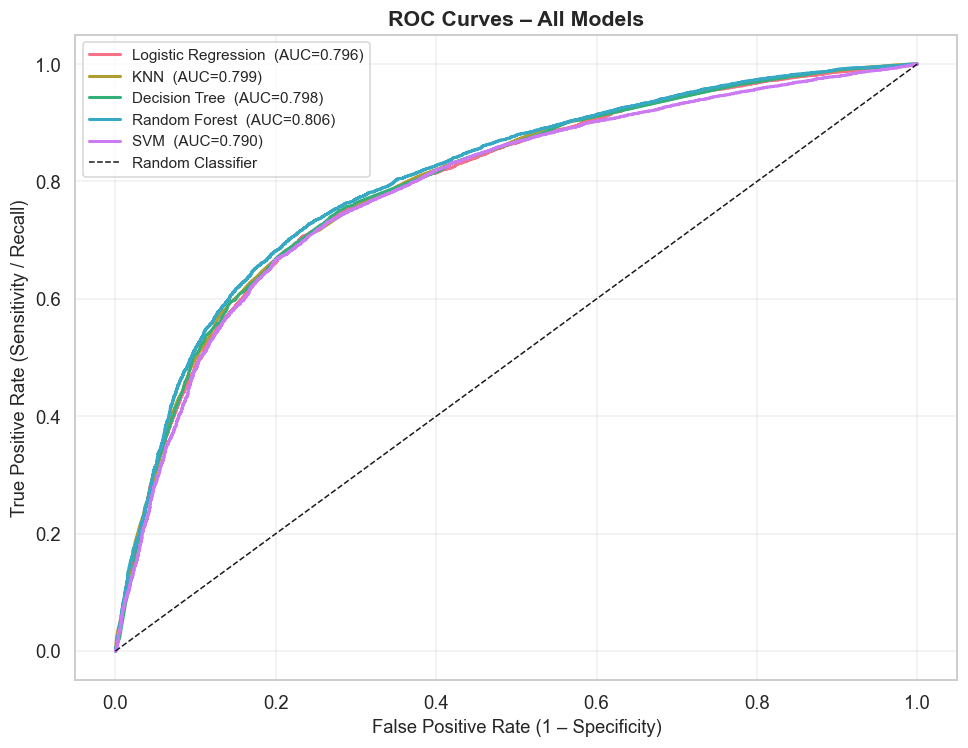

In [29]:
# ── ROC Curves ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
palette = sns.color_palette("husl", len(fitted_models))

for (name, pipe), color in zip(fitted_models.items(), palette):
    y_proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name}  (AUC={auc:.3f})", color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier")
ax.set_xlabel("False Positive Rate (1 – Specificity)", fontsize=12)
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
ax.set_title("ROC Curves – All Models", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "15_all_roc_curves.png"), dpi=150)
plt.show()


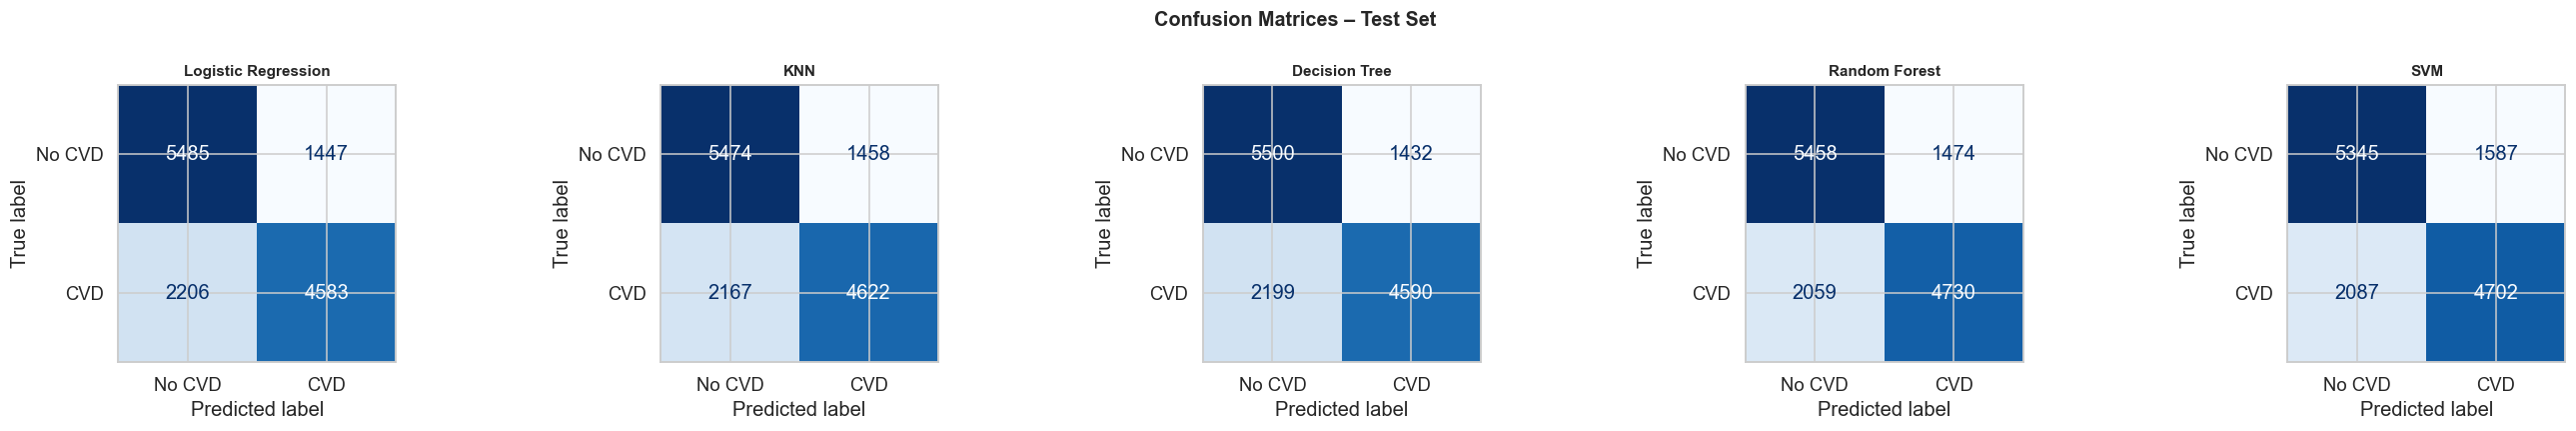

In [30]:
# ── Confusion Matrices ────────────────────────────────────────
n = len(fitted_models)
fig, axes = plt.subplots(1, n, figsize=(5*n, 4))

for ax, (name, pipe) in zip(axes, fitted_models.items()):
    y_pred = pipe.predict(X_test)
    cm     = confusion_matrix(y_test, y_pred)
    disp   = ConfusionMatrixDisplay(cm, display_labels=["No CVD", "CVD"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10, fontweight="bold")

plt.suptitle("Confusion Matrices – Test Set", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "16_confusion_matrices.png"), dpi=150, bbox_inches="tight")
plt.show()


## 10. Final Model Selection & Saving <a id='final'></a>

**Selection criteria:**
1. Highest ROC-AUC (primary — reflects discriminative ability at all thresholds)
2. High Recall (for screening, missing CVD is most harmful)
3. Reasonable F1-score (balance of precision and recall)
4. Computational feasibility

The model is refit on the **full training split** and evaluated **once** on test data.


In [31]:
# Select model with highest ROC-AUC
best_name = results_df.index[0]
print(f"Selected model: {best_name}")
print(f"  ROC-AUC : {results_df.loc[best_name, 'ROC_AUC']:.4f}")
print(f"  Recall  : {results_df.loc[best_name, 'Recall']:.4f}")
print(f"  F1-Score: {results_df.loc[best_name, 'F1']:.4f}")
print(f"\nRationale: {best_name} achieves the best ROC-AUC on the test set,")
print(f"indicating the strongest ability to discriminate CVD from non-CVD")
print(f"across all probability thresholds. For a cardiovascular screening")
print(f"tool, we value models that maximise recall (sensitivity) to minimise")
print(f"missed cases while maintaining reasonable precision.")

# Use final selected fitted pipeline
final_pipe = fitted_models[best_name]

y_final_pred  = final_pipe.predict(X_test)
y_final_proba = final_pipe.predict_proba(X_test)[:, 1]

print("\n=== FINAL MODEL — Held-Out Test Set Metrics ===")
print(f"  Accuracy  : {accuracy_score(y_test, y_final_pred):.4f}")
print(f"  Precision : {precision_score(y_test, y_final_pred):.4f}")
print(f"  Recall    : {recall_score(y_test, y_final_pred):.4f}")
print(f"  F1-Score  : {f1_score(y_test, y_final_pred):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_test, y_final_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_final_pred, target_names=["No CVD (0)", "CVD (1)"]))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))


Selected model: Random Forest
  ROC-AUC : 0.8061
  Recall  : 0.6967
  F1-Score: 0.7281

Rationale: Random Forest achieves the best ROC-AUC on the test set,
indicating the strongest ability to discriminate CVD from non-CVD
across all probability thresholds. For a cardiovascular screening
tool, we value models that maximise recall (sensitivity) to minimise
missed cases while maintaining reasonable precision.



=== FINAL MODEL — Held-Out Test Set Metrics ===
  Accuracy  : 0.7425
  Precision : 0.7624
  Recall    : 0.6967
  F1-Score  : 0.7281
  ROC-AUC   : 0.8061

Classification Report:
              precision    recall  f1-score   support

  No CVD (0)       0.73      0.79      0.76      6932
     CVD (1)       0.76      0.70      0.73      6789

    accuracy                           0.74     13721
   macro avg       0.74      0.74      0.74     13721
weighted avg       0.74      0.74      0.74     13721


Confusion Matrix:
[[5458 1474]
 [2059 4730]]


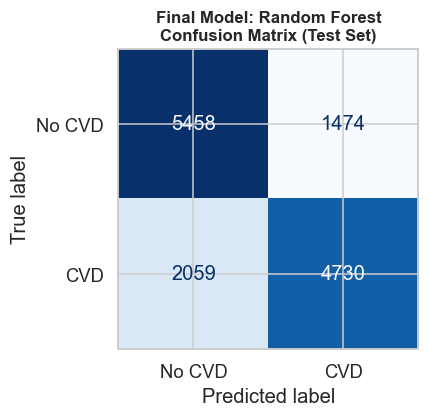

In [32]:
# ── Final confusion matrix plot ───────────────────────────────
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_final_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["No CVD", "CVD"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Final Model: {best_name}\nConfusion Matrix (Test Set)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "17_final_confusion_matrix.png"), dpi=150)
plt.show()


In [33]:
# ── Save model ────────────────────────────────────────────────
model_save_path = os.path.join(MODELS_DIR, "heart_disease_model.joblib")
joblib.dump(final_pipe, model_save_path)
print(f"✅ Model saved to: {model_save_path}")
print(f"   Model type: {type(final_pipe.named_steps['clf']).__name__}")


✅ Model saved to: D:\Project\heart-disease-prediction\models\heart_disease_model.joblib
   Model type: RandomForestClassifier


## 11. Prediction Function Demo <a id='prediction'></a>

The `predict_cardiovascular_risk()` function in `src/predict.py` accepts
individual health attributes and returns a prediction with an appropriate
medical disclaimer.


In [34]:
from src.predict import predict_cardiovascular_risk

MODEL_PATH = os.path.join(MODELS_DIR, "heart_disease_model.joblib")

print("=" * 60)
print("DEMO: Cardiovascular Disease Risk Prediction")
print("=" * 60)

# ── Profile 1: Healthy young person ───────────────────────────
print("\n▶ Profile 1 – Healthy 38-year-old female:")
r1 = predict_cardiovascular_risk(
    age_years=38, gender=1, height_cm=162, weight_kg=58,
    ap_hi=115, ap_lo=75, cholesterol=1, gluc=1,
    smoke=0, alco=0, active=1,
    model_path=MODEL_PATH,
)
print(f"  Risk Label  : {r1['risk_label']}")
print(f"  CVD Prob    : {r1['cvd_probability']:.4f}  ({r1['cvd_probability']*100:.1f}%)")
print(f"  Predicted   : {'CVD' if r1['predicted_class'] == 1 else 'No CVD'}")
print(f"  BMI         : {r1['input_summary']['bmi']}")
print(f"  Disclaimer  : {r1['disclaimer']}")


DEMO: Cardiovascular Disease Risk Prediction

▶ Profile 1 – Healthy 38-year-old female:


  Risk Label  : Low Risk
  CVD Prob    : 0.0864  (8.6%)
  Predicted   : No CVD
  BMI         : 22.1
  Disclaimer  : ⚠️  This is a machine-learning prediction based on statistical patterns in a population dataset.  It is NOT a clinical diagnosis.  Please consult a qualified healthcare professional for medical advice.


In [35]:
# ── Profile 2: High-risk elderly male ─────────────────────────
print("\n▶ Profile 2 – High-risk 62-year-old male:")
r2 = predict_cardiovascular_risk(
    age_years=62, gender=2, height_cm=172, weight_kg=98,
    ap_hi=175, ap_lo=105, cholesterol=3, gluc=3,
    smoke=1, alco=1, active=0,
    model_path=MODEL_PATH,
)
print(f"  Risk Label  : {r2['risk_label']}")
print(f"  CVD Prob    : {r2['cvd_probability']:.4f}  ({r2['cvd_probability']*100:.1f}%)")
print(f"  Predicted   : {'CVD' if r2['predicted_class'] == 1 else 'No CVD'}")
print(f"  BMI         : {r2['input_summary']['bmi']}")
print(f"  Disclaimer  : {r2['disclaimer']}")



▶ Profile 2 – High-risk 62-year-old male:
  Risk Label  : High Risk
  CVD Prob    : 0.8515  (85.2%)
  Predicted   : CVD
  BMI         : 33.13
  Disclaimer  : ⚠️  This is a machine-learning prediction based on statistical patterns in a population dataset.  It is NOT a clinical diagnosis.  Please consult a qualified healthcare professional for medical advice.


In [36]:
# ── Profile 3: Invalid input – error handling demo ────────────
print("\n▶ Profile 3 – Invalid input (diastolic > systolic):")
try:
    predict_cardiovascular_risk(
        age_years=50, gender=1, height_cm=165, weight_kg=70,
        ap_hi=80, ap_lo=120,   # Physiologically invalid
        cholesterol=1, gluc=1, smoke=0, alco=0, active=1,
        model_path=MODEL_PATH,
    )
except ValueError as e:
    print(f"  ✅ Correctly raised ValueError: {e}")



▶ Profile 3 – Invalid input (diastolic > systolic):
  ✅ Correctly raised ValueError: Diastolic pressure (ap_lo=120) must be strictly less than systolic pressure (ap_hi=80).


## Summary

### Project Deliverables

| File | Description |
|------|-------------|
| `data/cardio_train.csv` | Raw dataset |
| `src/preprocessing.py` | Data loading & cleaning pipeline |
| `src/train_model.py` | Training, tuning, evaluation & saving |
| `src/predict.py` | Reusable prediction function |
| `notebooks/heart_disease_analysis.ipynb` | This notebook |
| `models/heart_disease_model.joblib` | Saved final pipeline |
| `outputs/model_comparison.csv` | Metric comparison table |
| `outputs/figures/` | All EDA and model plots |
| `requirements.txt` | Python dependencies |
| `README.md` | Full project documentation |

### ⚠️ Safety Notice
All model predictions are based on statistical patterns in a population-level dataset.
They are **NOT clinical diagnoses** and must **not** replace professional medical evaluation.
